The notebook collects personas string and embeddings, and tries to study their similarity with different approaches

In [54]:
import json
from pathlib import Path

folder = Path(
  "data/subj/"
)

with open(folder / "personas.json") as f:
  r = json.load(f)

r

[{'persona': 'Hispanic male in his 30s–40s living in the US West, single, agnostic, very liberal Democrat, living alone and working full-time with mid income and some college. Socially somewhat reserved but generally cooperative and warm; highly empathetic and environmentally minded, and wants to be seen as dependable, respected, and improving—though not necessarily loved by everyone. Emotionally reactive with elevated anxiety and stress sensitivity, preferring clarity and closure and often seeking the “best” option rather than settling, which can lead to worry or second-guessing. Not especially curious about abstract/novel ideas and tends to avoid heavy cognitive effort, yet can be logically reflective when prompted and is not prone to overconfidence. Financially tends toward impulsive spending and uses mental “buckets” for money; has only moderate comfort with numbers/financial concepts. In negotiations and sharing situations he aims to keep the majority while still maintaining a sen

In [55]:
strings = [p['persona'] for p in r]
embeddings_pca10 = [p['embedding_pca10'] for p in r]

In [56]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

X = np.array(embeddings_pca10)

metrics = [
    'euclidean',
    'sqeuclidean',
    'cityblock',
    'cosine',
    'chebyshev',
    'correlation',
    'minkowski',
    'mahalanobis',
]

matrices = {}

for metric in metrics:
    if metric == 'minkowski':
        distances = pdist(X, metric=metric, p=3)
    else:
        distances = pdist(X, metric=metric)

    matrices[metric] = squareform(distances)

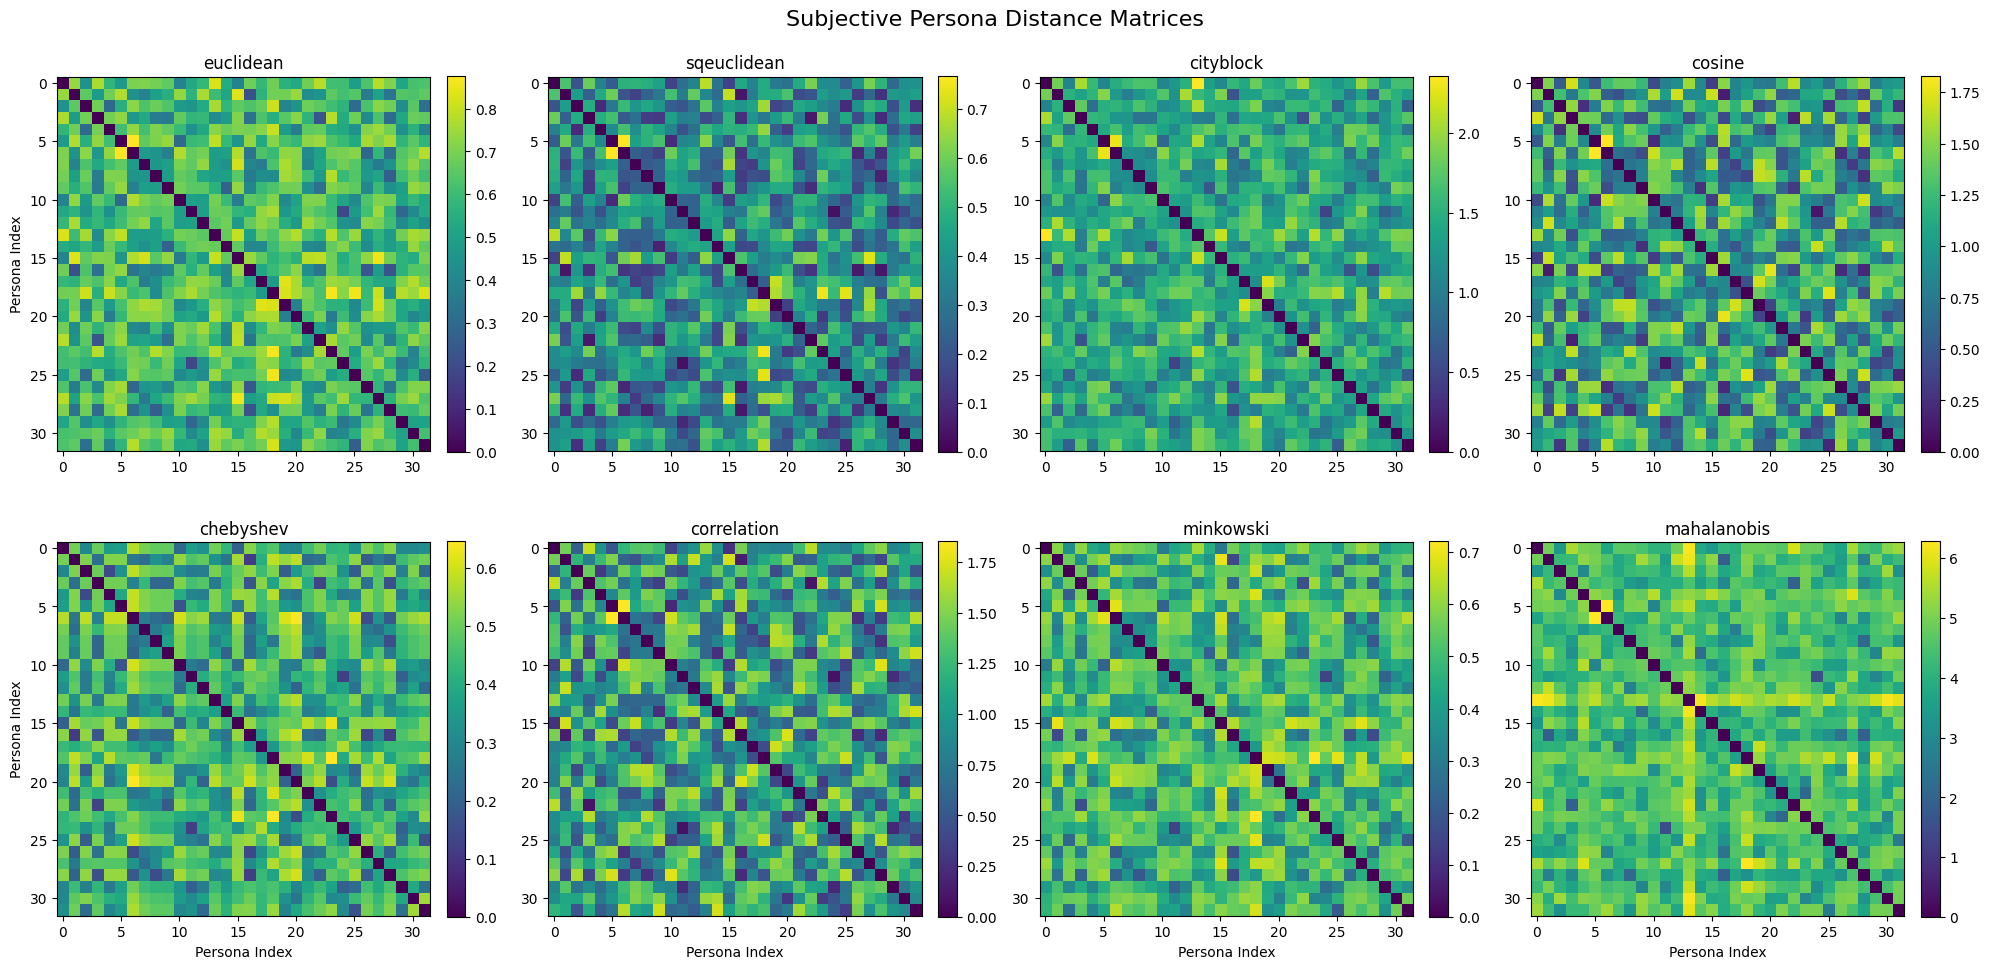

In [57]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, (metric, matrix) in enumerate(matrices.items()):
    ax = axes[i]

    im = ax.imshow(matrix, cmap='viridis', interpolation='nearest')
    ax.set_title(metric)

    # Show axis labels only on the outer plots
    if i // 4 == 1:
        ax.set_xlabel('Persona Index')

    if i % 4 == 0:
        ax.set_ylabel('Persona Index')

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('Subjective Persona Distance Matrices', fontsize=16)
plt.tight_layout()
plt.show()

### Top 3 best match

In [58]:
import textwrap

for metric, matrix in matrices.items():
    print("===================================")
    print(f"\nMETRIC: {metric}")
    print("===================================")
    # Get the indices of the upper triangle of the matrix, excluding the diagonal
    triu_indices = np.triu_indices_from(matrix, k=1)
    # Get the distances for those indices
    distances = matrix[triu_indices]
    # Get the indices of the sorted distances
    sorted_indices = np.argsort(distances)
    # Get the top 3 closest pairs
    top_3_indices = sorted_indices[:3]

    for idx in top_3_indices:
        i, j = triu_indices[0][idx], triu_indices[1][idx]

        print(f"\nPair: ({i}, {j}), Distance: {distances[idx]}")

        print("Persona (a):")
        print(f"    {textwrap.fill(strings[i], width=80, subsequent_indent='    ')}")
        print("Persona (b):")
        print(f"    {textwrap.fill(strings[j], width=80, subsequent_indent='    ')}")

print()


METRIC: euclidean

Pair: (11, 24), Distance: 0.18859005275596996
Persona (a):
    Midwestern white male (30–49), divorced, agnostic, politically
    moderate/independent, highly educated and high-earning, working full-time in
    a household of four. He is extremely conscientious, disciplined, and
    standards-driven—reliable, organized, and persistent—but also relatively low
    in warmth/agreeableness and empathy, so he can come across as blunt,
    impatient, or easily frustrated when others don’t meet expectations. More
    reserved than outgoing, emotionally steady with generally low anxiety, and
    moderately open to new ideas without seeking novelty for its own sake; he’s
    comfortable with ambiguity and tends to satisfice rather than obsess over
    “perfect” choices. Cognitively, he enjoys thinking through complex problems
    and shows strong reflective reasoning, numeracy, and financial literacy; he
    uses clear mental “budgets” and categories for money, is moderately

### Top 3 worst match

In [59]:
import textwrap

for metric, matrix in matrices.items():
    print("===================================")
    print(f"\nMETRIC: {metric}")
    print("===================================")
    # Get the indices of the upper triangle of the matrix, excluding the diagonal
    triu_indices = np.triu_indices_from(matrix, k=1)
    # Get the distances for those indices
    distances = matrix[triu_indices]
    # Get the indices of the sorted distances
    sorted_indices = np.argsort(distances)
    # Get the top 3 farthest pairs
    top_3_indices = sorted_indices[-3:]

    for idx in top_3_indices:
        i, j = triu_indices[0][idx], triu_indices[1][idx]

        print(f"\nPair: ({i}, {j}), Distance: {distances[idx]}")

        print("Persona (a):")
        print(f"    {textwrap.fill(strings[i], width=80, subsequent_indent='    ')}")
        print("Persona (b):")
        print(f"    {textwrap.fill(strings[j], width=80, subsequent_indent='    ')}")

print()


METRIC: euclidean

Pair: (18, 25), Distance: 0.8572316796918362
Persona (a):
    Married Hispanic Catholic woman (30–49) in the Western US with postgraduate
    education, a homemaker in a four-person household and moderate/independent
    politics. She is organized, tidy, and responsibility-driven, prioritizing
    family stability and fairness, and tends to be nurturing and patient with
    her children while more easily irritated with her spouse; she aspires to
    stay calm, logical, manage time better, and build financial independence.
    Socially she is middle-of-the-road (not strongly outgoing), somewhat
    pragmatic rather than novelty-seeking, and values both getting ahead and
    maintaining harmony, with strong loyalty to her in-group and respect for
    family roles. Decision-wise she thinks things through and likes optimizing
    choices, but can be overconfident in her judgments and may present herself
    in a socially acceptable light; she prefers clear, structured o

In [60]:
# create dataframe as follows:
# each row is a persona, each column is a component of the embedding

import pandas as pd

df = pd.DataFrame(embeddings_pca10, columns=[f"pc_{i}" for i in range(len(embeddings_pca10[0]))])
df.head()

,pc_0,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6,pc_7,pc_8,pc_9
0,-0.250722,0.189248,-0.161713,0.049649,-0.171334,0.091917,-0.028269,0.036100,-0.170062,0.078953
1,0.261353,-0.172007,-0.000167,0.031534,0.040702,0.201649,-0.097064,0.082417,0.004790,-0.111278
2,-0.257002,-0.108221,-0.064579,-0.205642,-0.116909,0.004934,-0.123170,0.070418,-0.064128,0.047303
3,0.244812,0.035654,0.229460,-0.091219,-0.025592,-0.035083,0.072278,-0.060061,0.107848,-0.048053
4,-0.261497,-0.162745,0.003480,-0.093133,-0.001279,-0.069486,-0.214781,-0.019479,0.079470,0.165637


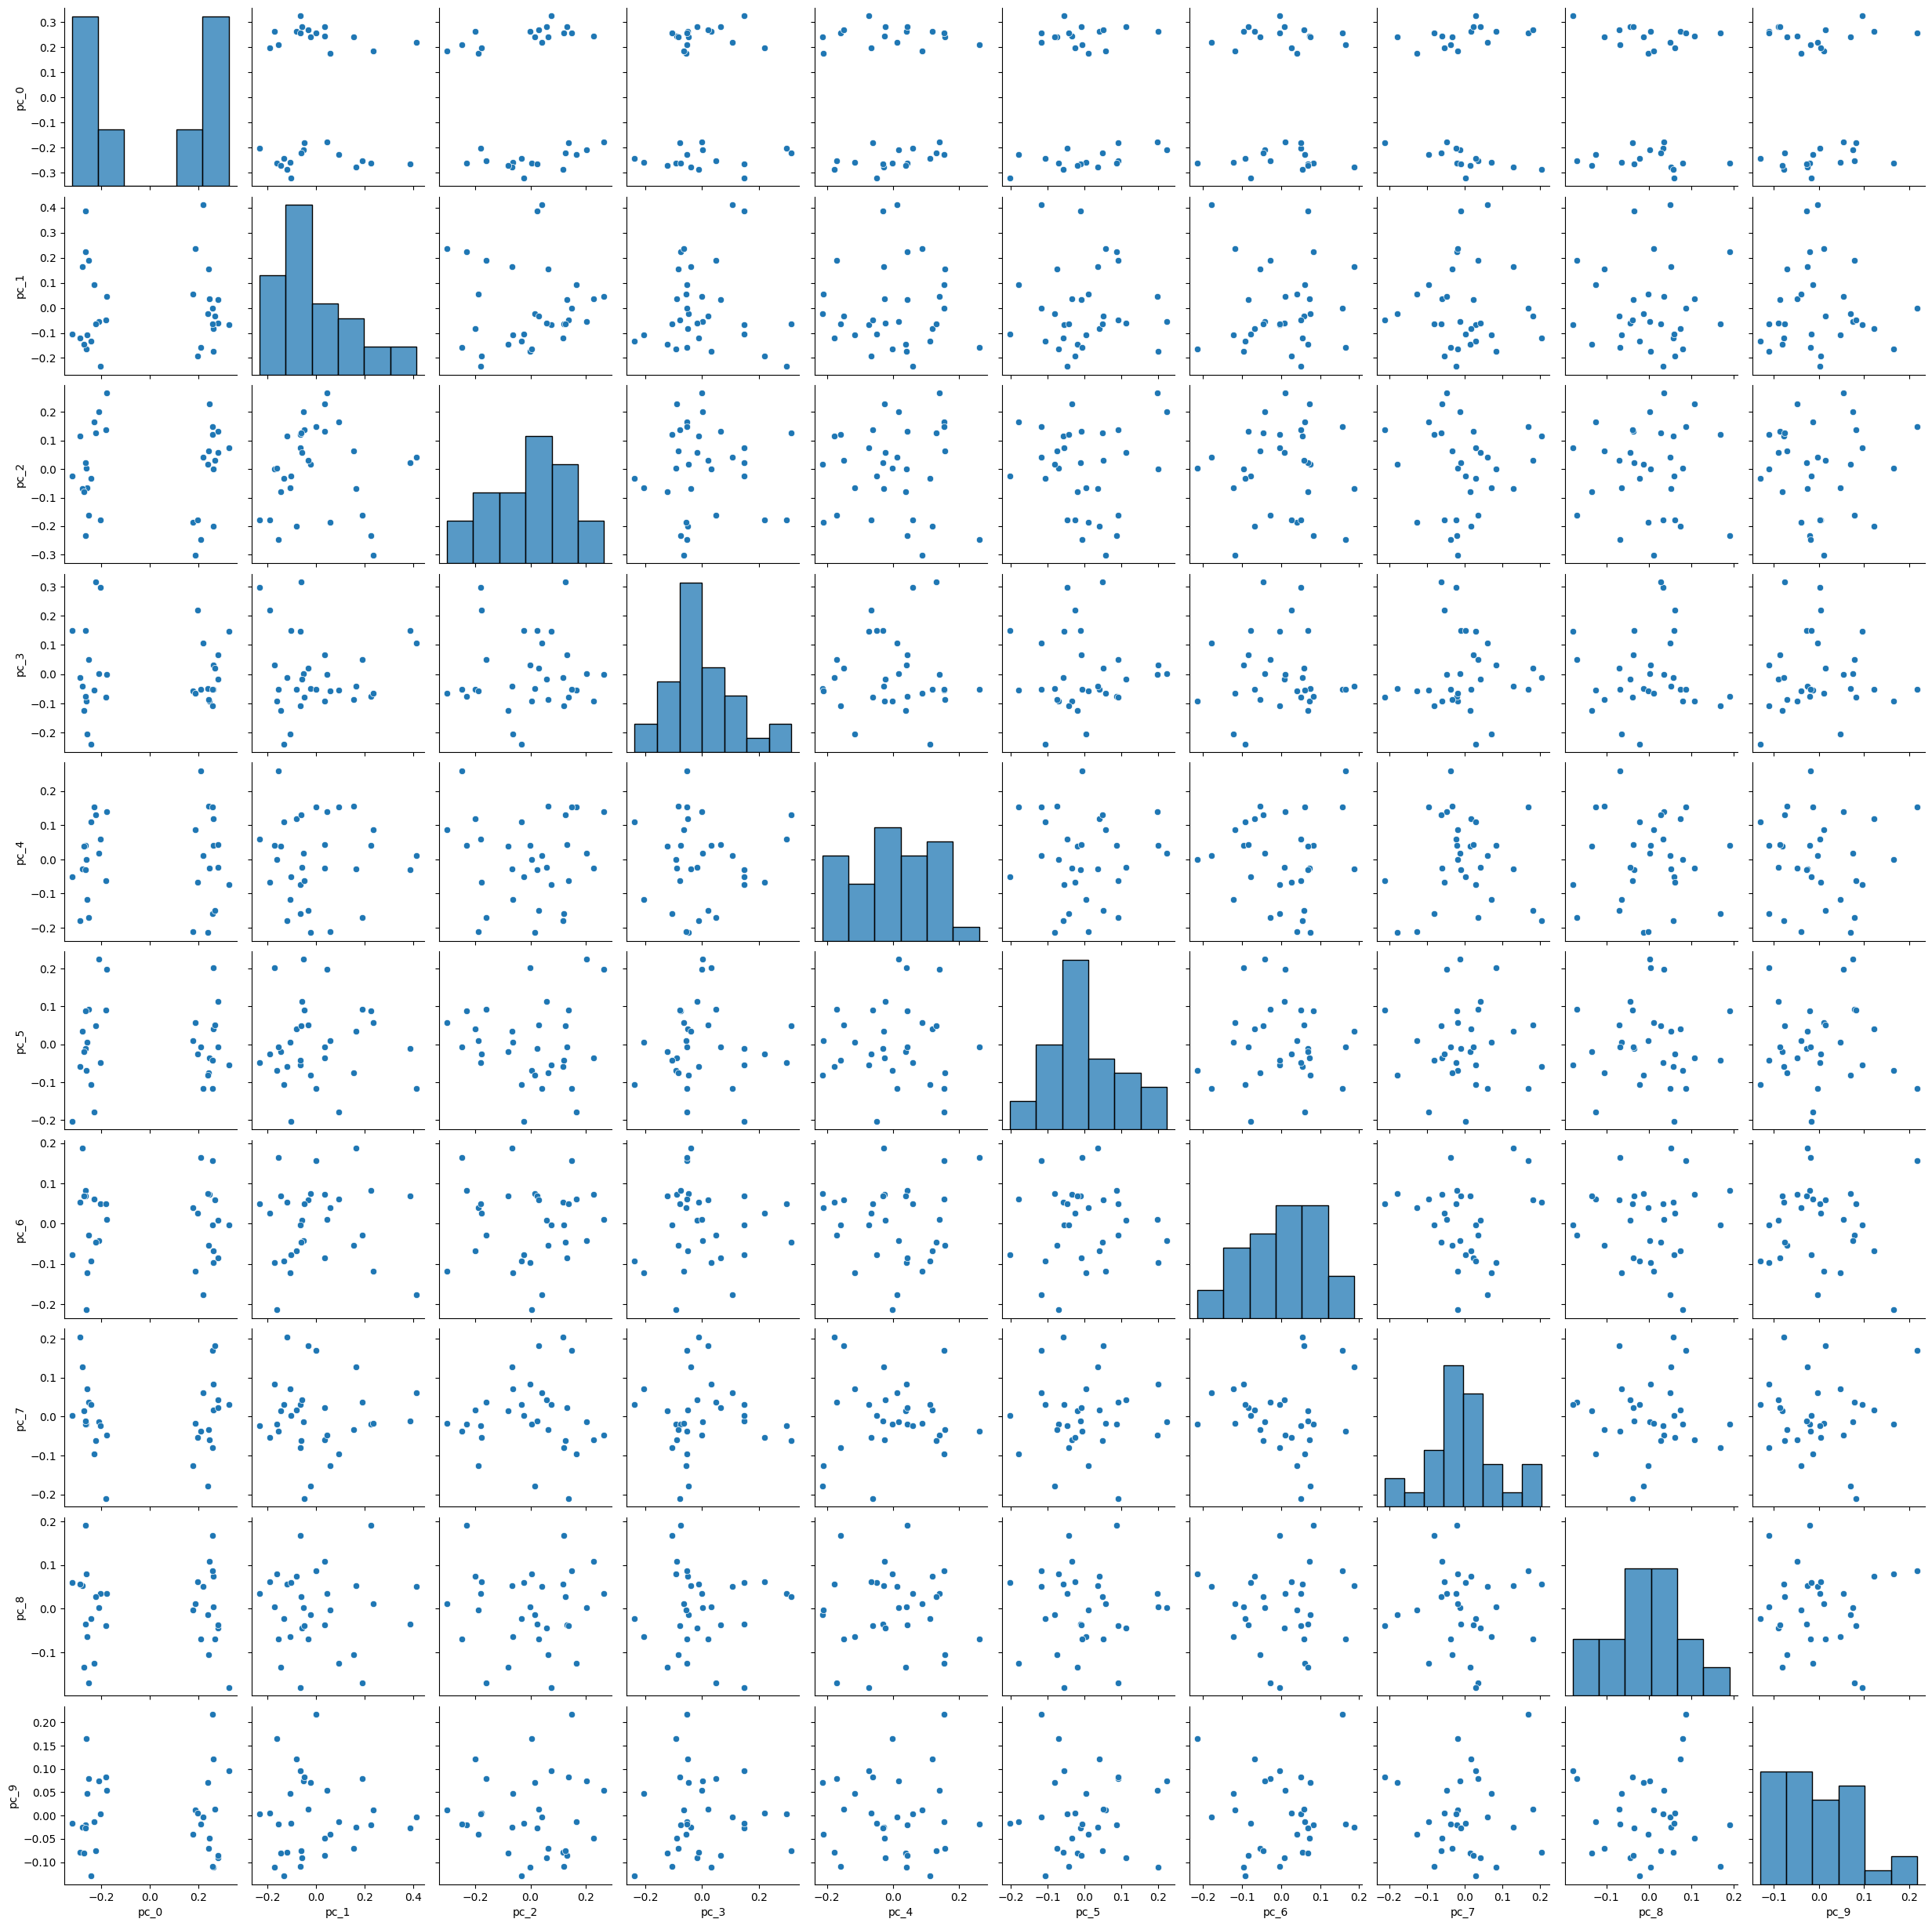

In [61]:
import seaborn as sns

sns.pairplot(df)

In [62]:
df.describe()

,pc_0,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6,pc_7,pc_8,pc_9
count,3.200000e+01,32.000000,3.200000e+01,3.200000e+01,3.200000e+01,3.200000e+01,3.200000e+01,3.200000e+01,3.200000e+01,3.200000e+01
mean,2.428613e-17,0.000000,-1.994932e-17,6.938894e-18,-4.597017e-17,-1.734723e-17,2.385245e-18,6.938894e-18,-5.204170e-18,7.806256e-18
std,2.511746e-01,0.161398,1.501893e-01,1.279836e-01,1.208188e-01,1.017556e-01,9.527226e-02,9.270508e-02,8.809936e-02,8.327004e-02
min,-3.198011e-01,-0.233879,-3.019833e-01,-2.386903e-01,-2.143108e-01,-2.031344e-01,-2.147812e-01,-2.112025e-01,-1.797091e-01,-1.300208e-01
25%,-2.522917e-01,-0.111128,-1.009082e-01,-7.620352e-02,-6.922592e-02,-6.136491e-02,-7.040808e-02,-4.975338e-02,-4.913305e-02,-7.153532e-02
50%,-4.309440e-04,-0.051171,2.011220e-02,-4.475392e-02,4.919141e-03,-8.989959e-03,9.269923e-03,-1.197957e-02,3.826184e-03,-1.460360e-02
75%,2.477982e-01,0.065031,1.221124e-01,5.377012e-02,9.344935e-02,5.323168e-02,6.262177e-02,3.762395e-02,5.772774e-02,5.871547e-02
max,3.244783e-01,0.412153,2.660196e-01,3.157652e-01,2.598239e-01,2.240330e-01,1.874207e-01,2.045774e-01,1.902689e-01,2.174097e-01


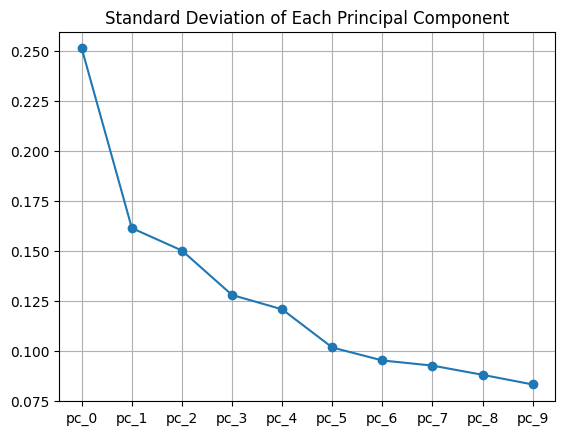

In [88]:
plt.plot(df.std(), '-o')
plt.title("Standard Deviation of Each Principal Component")
plt.grid()
plt.show()

### UMAP (original vs 10pca)

use n_neighbors=5 or 10 and see the difference

In [64]:
# Load your provided JSON file
with open("data/subj/persona_embeddings.json", "r", encoding="utf-8") as f:
    data = json.load(f)

# Extract the original embeddings
full_embeddings = np.array([
    item["embedding"] for item in data["items"]
])

print("Embedding shape:", full_embeddings.shape)
print("Dimensions per embedding:", full_embeddings.shape[1])

Embedding shape: (32, 1536)
Dimensions per embedding: 1536


/Users/leo/.pyenv/versions/3.9.13/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/var/folders/fs/k53t7dxj1zqbyfqnmt7mn8r80000gn/T/ipykernel_63918/3056484113.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('turbo', 32)


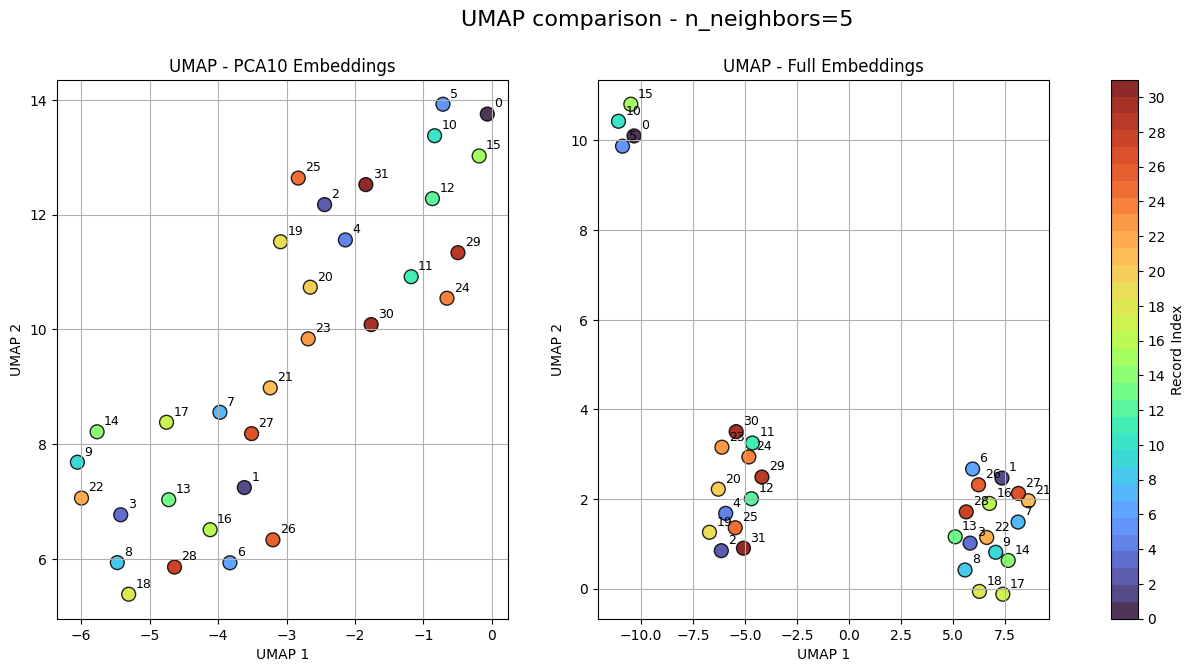

In [84]:
import umap

n_neighbors = 5
reducer = umap.UMAP(
    n_neighbors=n_neighbors,
    min_dist=0.5,
    metric='cosine',
    random_state=42
)

reduced_embeddings_pca10 = reducer.fit_transform(embeddings_pca10)
reduced_embeddings_full = reducer.fit_transform(full_embeddings)

# Same color for the same record index
indices = np.arange(32)
cmap = plt.cm.get_cmap('turbo', 32)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, data, title in zip(
    axes,
    [reduced_embeddings_pca10, reduced_embeddings_full],
    ['UMAP - PCA10 Embeddings', 'UMAP - Full Embeddings']
):
    scatter = ax.scatter(
        data[:, 0],
        data[:, 1],
        c=indices,
        cmap=cmap,
        vmin=0,
        vmax=31,
        s=100,
        edgecolors='black',
        alpha=0.85
    )

    # Add record index labels
    for i, (x, y) in enumerate(data):
        ax.annotate(
            str(i),
            (x, y),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=9
        )

    ax.set_title(title)
    ax.grid()
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

# Shared colorbar
cbar = fig.colorbar(scatter, ax=axes, ticks=np.arange(0, 32, 2))
cbar.set_label('Record Index')

plt.suptitle(f'UMAP comparison - n_neighbors={n_neighbors}', fontsize=16)
plt.savefig(f"figures/umap_comparison_n_neighbors_{n_neighbors}.pdf")

plt.show()


### t-SNE (original vs 10pca)

Like UMAP, try perplexity=5 or 10 to see the differences

/var/folders/fs/k53t7dxj1zqbyfqnmt7mn8r80000gn/T/ipykernel_63918/2794518947.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('turbo', 32)


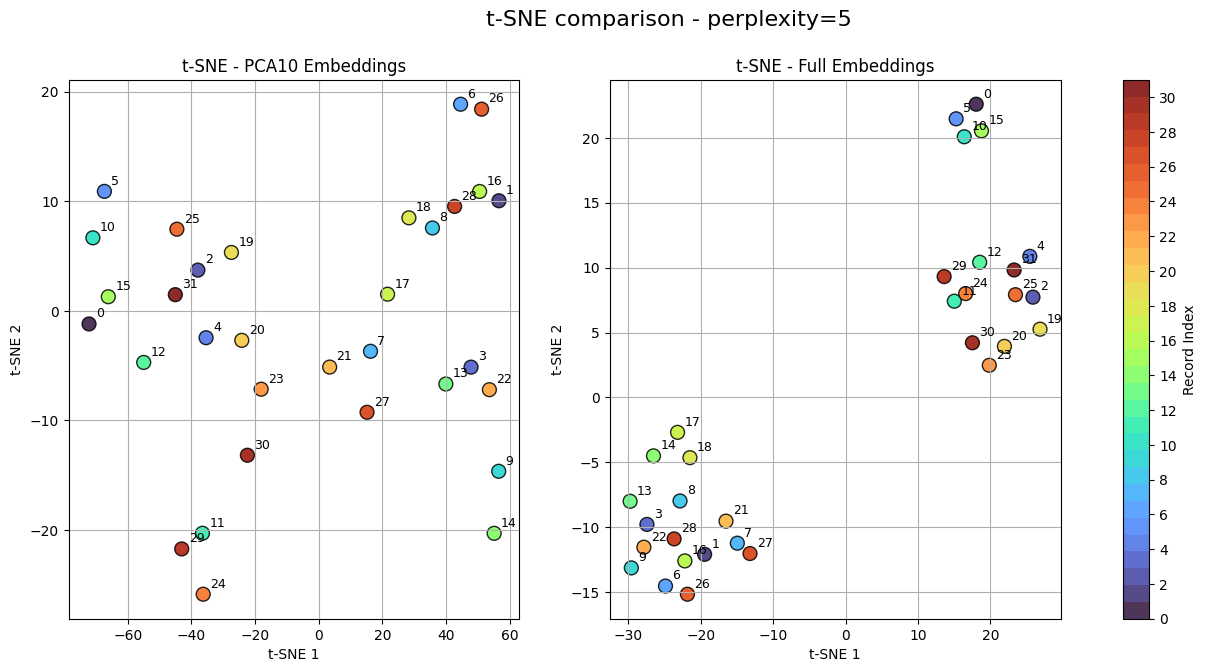

In [94]:
from sklearn.manifold import TSNE

perplexity = 5

reducer = TSNE(
    n_components=2,
    perplexity=perplexity,
    metric='cosine',
    init='random',
    learning_rate='auto',
    random_state=42
)

embeddings_pca10 = np.asarray(embeddings_pca10, dtype=float)
full_embeddings = np.asarray(full_embeddings, dtype=float)

# Apply t-SNE to PCA10 embeddings
reduced_embeddings_pca10 = reducer.fit_transform(
    embeddings_pca10
)

# Apply t-SNE to full embeddings
reduced_embeddings_full = reducer.fit_transform(
    full_embeddings
)

# Same color for the same record index
indices = np.arange(32)
cmap = plt.cm.get_cmap('turbo', 32)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, data, title in zip(
    axes,
    [reduced_embeddings_pca10, reduced_embeddings_full],
    ['t-SNE - PCA10 Embeddings', 't-SNE - Full Embeddings']
):
    scatter = ax.scatter(
        data[:, 0],
        data[:, 1],
        c=indices,
        cmap=cmap,
        vmin=0,
        vmax=31,
        s=100,
        edgecolors='black',
        alpha=0.85
    )

    # Add record index labels
    for i, (x, y) in enumerate(data):
        ax.annotate(
            str(i),
            (x, y),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=9
        )

    ax.set_title(title)
    ax.grid()
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')

# Shared colorbar
cbar = fig.colorbar(
    scatter,
    ax=axes,
    ticks=np.arange(0, 32, 2)
)
cbar.set_label('Record Index')

plt.suptitle(
    f't-SNE comparison - perplexity={perplexity}',
    fontsize=16
)

plt.savefig(
    f"figures/tsne_comparison_perplexity_{perplexity}.pdf",
)

plt.show()


There is a quite clear cluster that groups together persona 0, 5, 10 and 15.

In [95]:
for index in [0,5,10,15]:
  print(f"Persona {index}: {strings[index]}")

Persona 0: Hispanic male in his 30s–40s living in the US West, single, agnostic, very liberal Democrat, living alone and working full-time with mid income and some college. Socially somewhat reserved but generally cooperative and warm; highly empathetic and environmentally minded, and wants to be seen as dependable, respected, and improving—though not necessarily loved by everyone. Emotionally reactive with elevated anxiety and stress sensitivity, preferring clarity and closure and often seeking the “best” option rather than settling, which can lead to worry or second-guessing. Not especially curious about abstract/novel ideas and tends to avoid heavy cognitive effort, yet can be logically reflective when prompted and is not prone to overconfidence. Financially tends toward impulsive spending and uses mental “buckets” for money; has only moderate comfort with numbers/financial concepts. In negotiations and sharing situations he aims to keep the majority while still maintaining a sense 

They are all Hispanic people, but not every Hispanic person is inside the cluster

In [97]:
for i in range(32):
  if "Hispanic" in strings[i]:
    print(f"Persona {i}: {strings[i]}")

Persona 0: Hispanic male in his 30s–40s living in the US West, single, agnostic, very liberal Democrat, living alone and working full-time with mid income and some college. Socially somewhat reserved but generally cooperative and warm; highly empathetic and environmentally minded, and wants to be seen as dependable, respected, and improving—though not necessarily loved by everyone. Emotionally reactive with elevated anxiety and stress sensitivity, preferring clarity and closure and often seeking the “best” option rather than settling, which can lead to worry or second-guessing. Not especially curious about abstract/novel ideas and tends to avoid heavy cognitive effort, yet can be logically reflective when prompted and is not prone to overconfidence. Financially tends toward impulsive spending and uses mental “buckets” for money; has only moderate comfort with numbers/financial concepts. In negotiations and sharing situations he aims to keep the majority while still maintaining a sense 